# Bài 18 · Phân cụm và mô hình chủ đề: khám phá văn bản không nhãn

**Thời lượng gợi ý:** 180 phút · **Cần:** Bài 2, Bài 12 (embedding câu) · **Không cần GPU** (lần đầu tính embedding mất ≈ 3 phút trên CPU, sau đó được lưu lại)

> **Bài mở rộng.** Ngoài đời, bạn thường có một đống văn bản *chưa có nhãn* (phản hồi, ticket, bình luận) và một câu hỏi mơ hồ: "khách hàng đang nói về những gì?". Phân cụm và mô hình chủ đề là công cụ khám phá. Bài này dạy cách dùng chúng **và cách không bị chúng đánh lừa**: một cụm trông "gọn" chưa chắc có nghĩa.

## Mục tiêu

1. Cài đặt **k-means** (khởi tạo k-means++) từ đầu và kiểm tra với scikit-learn.
2. So hai cách biểu diễn: **TF-IDF + SVD** và **embedding câu** (Bài 12), trên dữ liệu thật và dữ liệu tổng hợp.
3. Đánh giá cụm theo **hai cách**: khi *không* có nhãn (silhouette, độ ổn định) và khi *có* nhãn tham chiếu (NMI, ARI, độ thuần), và hiểu vì sao chúng có thể bất đồng.
4. **Đọc hiểu cụm**: từ khóa c-TF-IDF và câu đại diện.
5. Chạy **LDA** và **NMF** cho tiếng Việt và đo **độ nhất quán chủ đề** (NPMI, tự cài).
6. Dùng embedding để tìm **câu gần trùng** và kiểm tra tính nhất quán nhãn (nối Bài 16).

In [1]:
import sys, pathlib

ROOT = pathlib.Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import warnings
warnings.filterwarnings("ignore")

import time
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import transformers
transformers.logging.set_verbosity_error()
from sklearn.cluster import KMeans
from sklearn.decomposition import LatentDirichletAllocation, NMF, TruncatedSVD
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import adjusted_rand_score as ari, normalized_mutual_info_score as nmi, silhouette_score
from sklearn.preprocessing import normalize

from nlpvi import load_splits, segment, set_seed

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
set_seed(42)

## 1. Phân cụm là gì, và nó trả lời câu hỏi nào?

Cho $n$ vector $z_i\in\mathbb R^d$ (mỗi vector biểu diễn một văn bản). **k-means** tìm $k$ tâm $\mu_1,\dots,\mu_k$ và gán mỗi điểm vào tâm gần nhất sao cho tổng bình phương khoảng cách tới tâm — **quán tính** (inertia) — nhỏ nhất:

$$\min_{\mu,\,c}\ \sum_{i=1}^{n}\lVert z_i-\mu_{c_i}\rVert^2$$

Thuật toán Lloyd lặp hai bước: (1) gán mỗi điểm vào tâm gần nhất; (2) cập nhật tâm bằng trung bình các điểm được gán. Kết quả phụ thuộc điểm khởi đầu nên ta dùng **k-means++** (chọn tâm đầu ngẫu nhiên, các tâm sau chọn ngẫu nhiên với xác suất tỉ lệ $D^2$ — khoảng cách bình phương tới tâm gần nhất đã chọn) và chạy nhiều lần lấy kết quả tốt nhất.

Điều k-means **không** làm: nó không biết "chủ đề" là gì. Nó chỉ nhóm các vector *gần nhau trong không gian biểu diễn bạn chọn*. Nếu trục khác biệt lớn nhất trong dữ liệu là cảm xúc thì cụm sẽ theo cảm xúc, kể cả khi bạn muốn chủ đề. Đó là chủ đề xuyên suốt bài này.

## 2. Dữ liệu

Hai bộ dữ liệu, để thấy cùng một thuật toán cho kết quả ngược nhau:

- **UIT-VSFC** (phản hồi sinh viên, ≈ 11,4 nghìn câu train). Mỗi câu có **hai nhãn tham chiếu** độc lập: *chủ đề* (giảng viên / chương trình đào tạo / cơ sở vật chất / khác) và *cảm xúc*. Ta **không dùng nhãn để phân cụm**, chỉ dùng để *chấm* cụm sau đó. Chủ đề rất lệch: giảng viên chiếm ≈ 71%.
- **Đánh giá tổng hợp của khóa học** (1,3 nghìn câu train), có `domain` (5 lĩnh vực: sản phẩm, ứng dụng, dịch vụ, khóa học, ẩm thực) và nhãn cảm xúc. Viết từ khuôn mẫu nên lĩnh vực hiện rõ qua từ vựng.

In [2]:
TEN_CHU_DE = ["giảng viên", "chương trình", "cơ sở vật chất", "khác"]
TEN_CAM_XUC = ["tiêu cực", "trung tính", "tích cực"]

def tai_uit():
    try:
        from datasets import load_dataset
        d = load_dataset("uitnlp/vietnamese_students_feedback", revision="refs/convert/parquet")["train"].to_pandas()
        return pd.DataFrame({"text": d["sentence"], "chu_de": d["topic"], "cam_xuc": d["sentiment"]})
    except Exception as e:
        print(f"⚠ Không tải được UIT-VSFC ({type(e).__name__}); mục 3–7 sẽ dùng kho tổng hợp và kết luận sẽ khác.")
        return None

uit = tai_uit()
tr_tong_hop = load_splits()[0]
tong_hop = pd.DataFrame({"text": tr_tong_hop["text"], "chu_de": tr_tong_hop["domain"].astype("category").cat.codes,
                         "cam_xuc": tr_tong_hop["label"].map({"tiêu cực": 0, "trung tính": 1, "tích cực": 2})})
if uit is None:
    uit = tong_hop.copy(); TEN_CHU_DE = sorted(tr_tong_hop["domain"].unique())
print("UIT-VSFC :", len(uit), "câu | chủ đề:", dict(zip(TEN_CHU_DE, np.bincount(uit["chu_de"]))), "| cảm xúc:", dict(zip(TEN_CAM_XUC, np.bincount(uit["cam_xuc"]))))
print("Tổng hợp :", len(tong_hop), "câu | lĩnh vực:", dict(zip(sorted(tr_tong_hop["domain"].unique()), np.bincount(tong_hop["chu_de"]))))

UIT-VSFC : 11426 câu | chủ đề: {'giảng viên': np.int64(8166), 'chương trình': np.int64(2201), 'cơ sở vật chất': np.int64(497), 'khác': np.int64(562)} | cảm xúc: {'tiêu cực': np.int64(5325), 'trung tính': np.int64(458), 'tích cực': np.int64(5643)}
Tổng hợp : 1262 câu | lĩnh vực: {'dịch vụ': np.int64(252), 'khóa học': np.int64(237), 'sản phẩm': np.int64(279), 'ẩm thực': np.int64(228), 'ứng dụng': np.int64(266)}


## 3. k-means từ đầu

In [3]:
def kmeans_tu_cai(Z, k, seed=0, so_lan_lap=100):
    """k-means++ rồi thuật toán Lloyd. Trả về (nhãn cụm, tâm, quán tính)."""
    rng = np.random.default_rng(seed)
    n = len(Z)
    tam = [Z[rng.integers(n)]]
    d2 = ((Z - tam[0]) ** 2).sum(1)
    for _ in range(1, k):
        i = rng.choice(n, p=d2 / d2.sum())                       # chọn tâm kế tiếp với xác suất ∝ D²
        tam.append(Z[i]); d2 = np.minimum(d2, ((Z - Z[i]) ** 2).sum(1))
    tam = np.array(tam)
    for _ in range(so_lan_lap):
        D = (Z ** 2).sum(1)[:, None] - 2 * Z @ tam.T + (tam ** 2).sum(1)[None]
        nhan = D.argmin(1)
        moi = np.array([Z[nhan == j].mean(0) if (nhan == j).any() else Z[rng.integers(n)] for j in range(k)])
        if np.allclose(moi, tam):
            break
        tam = moi
    D = (Z ** 2).sum(1)[:, None] - 2 * Z @ tam.T + (tam ** 2).sum(1)[None]
    nhan = D.argmin(1)
    return nhan, tam, float(D[np.arange(n), nhan].sum())

# Kiểm tra với scikit-learn trên dữ liệu tổng hợp nhỏ (TF-IDF → SVD)
tf_ts = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
Z_ts_tfidf = normalize(TruncatedSVD(50, random_state=0).fit_transform(tf_ts.fit_transform(tong_hop["text"])))
k = 5
t0 = time.time()
ket = [kmeans_tu_cai(Z_ts_tfidf, k, seed=s) for s in range(5)]
t_tu = time.time() - t0
tot = min(ket, key=lambda r: r[2])
sk = KMeans(k, n_init=5, random_state=0).fit(Z_ts_tfidf)
print(f"Tự cài (5 lần khởi tạo): quán tính tốt nhất {tot[2]:.2f} | scikit-learn (n_init=5): {sk.inertia_:.2f}")
print(f"ARI giữa hai lời giải: {ari(tot[0], sk.labels_):.3f}  (1 = cùng một cách chia)")

Tự cài (5 lần khởi tạo): quán tính tốt nhất 1043.73 | scikit-learn (n_init=5): 1043.80
ARI giữa hai lời giải: 0.811  (1 = cùng một cách chia)


**Đọc kết quả (3).** Bản tự cài đạt quán tính 1043,73, sát với scikit-learn (1043,80): cài đặt đúng. Nhưng hai lời giải có quán tính *gần như bằng nhau* lại chỉ giống nhau ở mức ARI = 0,81, tức là **không phải cùng một cách chia**. Hàm mục tiêu của k-means có nhiều cực tiểu địa phương cho quán tính gần nhau mà cách chia khác nhau; quán tính thấp hơn một chút không có nghĩa là cách chia "đúng" hơn.

## 4. Hai cách biểu diễn

- **TF-IDF → SVD 100 chiều** (Bài 2): dựa vào *từ xuất hiện*; nhanh, không cần mô hình tải về.
- **Embedding câu `multilingual-e5-small`** (Bài 12): dựa vào *nghĩa*, huấn luyện sẵn; cần tính (≈ 3 phút cho 11,4 nghìn câu trên CPU lần đầu), kết quả lưu vào `outputs/cache/` để lần sau dùng lại.

Mọi vector đều chuẩn hóa L2 nên khoảng cách Euclid tương đương khoảng cách cosine.

In [4]:
CACHE = ROOT / "outputs" / "cache"
CACHE.mkdir(parents=True, exist_ok=True)

def nhung_e5(texts, ten):
    f = CACHE / f"emb_{ten}_e5small.npy"
    if f.exists():
        Z = np.load(f)
        if len(Z) == len(texts):
            return Z
    from nlpvi.retrieval import Embedder
    e5 = Embedder("intfloat/multilingual-e5-small", query_prefix="query: ", passage_prefix="passage: ", device="cpu", max_length=64)
    t0 = time.time(); Z = e5.encode(list(texts), "query", batch_size=128)
    np.save(f, Z); print(f"  đã tính embedding {ten}: {Z.shape} trong {time.time() - t0:.0f}s")
    return Z

def tfidf_svd(texts, d=100):
    tf = TfidfVectorizer(ngram_range=(1, 2), min_df=3, sublinear_tf=True)
    X = tf.fit_transform(texts)
    return normalize(TruncatedSVD(d, random_state=0).fit_transform(X))

Z_uit = {"TF-IDF + SVD": tfidf_svd(uit["text"]), "e5-small": nhung_e5(uit["text"], "uit")}
Z_th = {"TF-IDF + SVD": tfidf_svd(tong_hop["text"], 50), "e5-small": nhung_e5(tong_hop["text"], "tonghop")}
print({k: v.shape for k, v in Z_uit.items()})

  đã tính embedding uit: (11426, 384) trong 175s


  đã tính embedding tonghop: (1262, 384) trong 12s


{'TF-IDF + SVD': (11426, 100), 'e5-small': (11426, 384)}


## 5. Đánh giá cụm: khi không có nhãn và khi có nhãn

**Không cần nhãn** (chỉ nhìn vào cụm):

- **Silhouette** của một điểm: $s=\frac{b-a}{\max(a,b)}$ với $a$ là khoảng cách trung bình tới các điểm cùng cụm và $b$ là tới cụm gần nhất khác; trung bình trên mọi điểm, trong $[-1,1]$.
- **Độ ổn định**: chạy k-means với hai seed khác nhau rồi đo ARI giữa hai cách chia. Cách chia không ổn định thì không đáng tin.

**Có nhãn tham chiếu** (chỉ để *chấm* — không bao giờ dùng để phân cụm):

- **NMI** (thông tin tương hỗ chuẩn hóa) và **ARI** (chỉ số Rand điều chỉnh) giữa cụm và nhãn; cả hai ≈ 0 nếu cụm không liên quan nhãn, = 1 nếu trùng khớp. NMI và ARI không cần số cụm bằng số nhãn.

NMI chủ đề  NMI cảm xúc  silhouette  ổn định (ARI 2 seed)
biểu diễn    k                                                            
TF-IDF + SVD 2        0.131        0.291       0.034                 0.999
             3        0.113        0.218       0.029                 0.793
             4        0.100        0.191       0.029                 0.865
             6        0.098        0.151       0.038                 0.502
             8        0.083        0.137       0.044                 0.517
             12       0.140        0.137       0.053                 0.589
e5-small     2        0.126        0.469       0.085                 1.000
             3        0.102        0.357       0.080                 0.989
             4        0.094        0.310       0.073                 0.997
             6        0.108        0.273       0.044                 0.505
             8        0.103        0.244       0.037                 0.423
             12       0.101        0.231       0.029                 0.544

19s


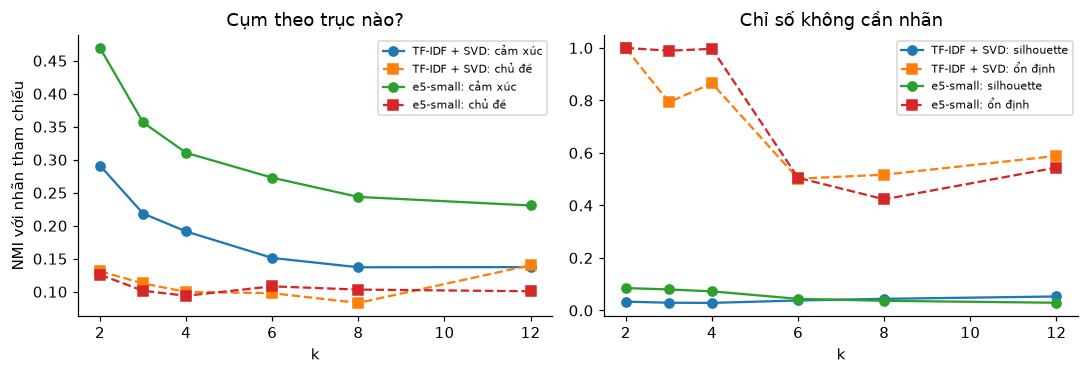

In [5]:
def quet_k(Z, ten_rep, ks=(2, 3, 4, 6, 8, 12)):
    rows = []
    for k in ks:
        nhan = KMeans(k, n_init=5, random_state=0).fit(Z).labels_
        a, b = KMeans(k, n_init=3, random_state=1).fit(Z).labels_, KMeans(k, n_init=3, random_state=2).fit(Z).labels_
        rows.append({"biểu diễn": ten_rep, "k": k, "NMI chủ đề": nmi(uit["chu_de"], nhan), "NMI cảm xúc": nmi(uit["cam_xuc"], nhan),
                     "silhouette": silhouette_score(Z, nhan, sample_size=3000, random_state=0), "ổn định (ARI 2 seed)": ari(a, b)})
    return rows

t0 = time.time()
bang_k = pd.DataFrame(sum([quet_k(Z, ten) for ten, Z in Z_uit.items()], [])).set_index(["biểu diễn", "k"])
display(bang_k.round(3))
print(f"{time.time() - t0:.0f}s")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
for ten in Z_uit:
    b = bang_k.loc[ten]
    ax[0].plot(b.index, b["NMI cảm xúc"], marker="o", label=f"{ten}: cảm xúc")
    ax[0].plot(b.index, b["NMI chủ đề"], marker="s", ls="--", label=f"{ten}: chủ đề")
    ax[1].plot(b.index, b["silhouette"], marker="o", label=f"{ten}: silhouette")
    ax[1].plot(b.index, b["ổn định (ARI 2 seed)"], marker="s", ls="--", label=f"{ten}: ổn định")
ax[0].set_xlabel("k"); ax[0].set_ylabel("NMI với nhãn tham chiếu"); ax[0].legend(fontsize=7); ax[0].set_title("Cụm theo trục nào?")
ax[1].set_xlabel("k"); ax[1].legend(fontsize=7); ax[1].set_title("Chỉ số không cần nhãn")
plt.tight_layout(); plt.show()

**Đọc kết quả (5).**

- **Cụm theo cảm xúc, không theo chủ đề.** Với e5, NMI với *cảm xúc* là 0,47 ở k = 2 và 0,31 ở k = 4, trong khi NMI với *chủ đề* chỉ 0,09–0,13 ở mọi k (TF-IDF: 0,29 ở k = 2 cho cảm xúc và 0,08–0,14 cho chủ đề). k-means đã tìm đúng trục khác biệt lớn nhất của dữ liệu — khen hay chê — chứ không phải trục ta gọi là "chủ đề". Nhãn chủ đề rất lệch (giảng viên 71%) cũng góp phần, nhưng điểm mấu chốt: **thuật toán không biết bạn muốn trục nào**.
- **Chỉ số không cần nhãn không giúp chọn k.** Silhouette rất thấp (0,03–0,09: không có cấu trúc cụm rõ). Với e5 nó cao nhất ở k = 2 (đúng là phép chia khen/chê) rồi giảm; với TF-IDF nó *tăng* theo k (0,034 → 0,053) nên không chỉ ra k nào.
- **Ổn định cao không có nghĩa là có ý nghĩa.** e5 ổn định tuyệt đối ở k = 2 (ARI = 1,00) và k = 3–4 (0,99–1,00), rồi rơi xuống 0,42–0,54 từ k ≥ 6: cách chia mịn hơn phụ thuộc điểm khởi tạo. Nhưng thứ ổn định nhất lại chính là phép chia khen/chê.

### 5.1 Cùng thuật toán, dữ liệu khác: trục chi phối đảo ngược

In [6]:
rows = []
for ten, Z in Z_th.items():
    for k in (3, 5, 8):
        nhan = KMeans(k, n_init=5, random_state=0).fit(Z).labels_
        rows.append({"biểu diễn": ten, "k": k, "NMI lĩnh vực": nmi(tong_hop["chu_de"], nhan), "NMI cảm xúc": nmi(tong_hop["cam_xuc"], nhan)})
display(pd.DataFrame(rows).set_index(["biểu diễn", "k"]).round(3))

NMI lĩnh vực  NMI cảm xúc
biểu diễn    k                           
TF-IDF + SVD 3         0.331        0.004
             5         0.711        0.008
             8         0.738        0.009
e5-small     3         0.010        0.162
             5         0.349        0.098
             8         0.527        0.058

**Đọc kết quả (5.1).** Cùng thuật toán, dữ liệu khác, và **trục chi phối đổi hẳn**. Trên kho tổng hợp (nhiều lĩnh vực, viết từ khuôn mẫu), TF-IDF + SVD phân cụm theo **lĩnh vực** (NMI 0,71 ở k = 5, đúng số lĩnh vực) và gần như bỏ qua cảm xúc (NMI < 0,01) — ngược hẳn UIT-VSFC, vốn chỉ có một lĩnh vực nên cảm xúc thành trục chi phối. Còn e5 ở k = 3 lại chia theo *cảm xúc* (0,16) chứ không theo lĩnh vực (0,01): **cách biểu diễn cũng quyết định trục** — TF-IDF nhạy với từ vựng đặc thù của lĩnh vực, embedding câu nhạy với ngữ nghĩa/cực tính. Hai bài học: (1) kết quả đẹp trên dữ liệu tổng hợp (NMI 0,71) không chuyển sang dữ liệu thật (≈ 0,1); (2) hãy chọn biểu diễn theo trục bạn muốn khám phá.

### 5.2 Gỡ trục không mong muốn có giúp không?

Nếu cảm xúc chi phối, thử **chiếu bỏ hướng cảm xúc** khỏi embedding trước khi phân cụm: huấn luyện bộ phân loại tuyến tính cảm xúc trên embedding, lấy các hướng (hệ số) của nó, trừ phần chiếu lên các hướng đó, chuẩn hóa lại. Đối chứng: chiếu bỏ 3 hướng *ngẫu nhiên*.

In [7]:
def chieu_bo(Z, W):
    Q, _ = np.linalg.qr(W.T)                                  # cơ sở trực chuẩn của không gian bị loại
    return normalize(Z - (Z @ Q) @ Q.T)

Z = Z_uit["e5-small"]
y_cx = uit["cam_xuc"].values
rng = np.random.default_rng(0)
cac_cach = {"gốc": Z, "bỏ 3 hướng ngẫu nhiên (đối chứng)": chieu_bo(Z, rng.standard_normal((3, Z.shape[1])))}
Z2 = Z.copy()
for vong in range(1, 6):
    clf = LogisticRegression(C=1, max_iter=2000).fit(Z2, y_cx)
    Z2 = chieu_bo(Z2, clf.coef_)
    if vong in (1, 5):
        cac_cach[f"bỏ hướng cảm xúc, {vong} vòng"] = Z2.copy()
rows = []
for ten, Zc in cac_cach.items():
    acc = LogisticRegression(C=1, max_iter=2000).fit(Zc, y_cx).score(Zc, y_cx)
    for k in (4, 8):
        nhan = KMeans(k, n_init=5, random_state=0).fit(Zc).labels_
        rows.append({"biến đổi": ten, "k": k, "đoán cảm xúc được (acc train)": round(acc, 3), "NMI chủ đề": nmi(uit["chu_de"], nhan), "NMI cảm xúc": nmi(y_cx, nhan)})
display(pd.DataFrame(rows).set_index(["biến đổi", "k"]).round(3))

đoán cảm xúc được (acc train)  \
biến đổi                          k                                  
gốc                               4                          0.910   
                                  8                          0.910   
bỏ 3 hướng ngẫu nhiên (đối chứng) 4                          0.911   
                                  8                          0.911   
bỏ hướng cảm xúc, 1 vòng          4                          0.838   
                                  8                          0.838   
bỏ hướng cảm xúc, 5 vòng          4                          0.653   
                                  8                          0.653   

                                     NMI chủ đề  NMI cảm xúc  
biến đổi                          k                           
gốc                               4       0.094        0.310  
                                  8       0.103        0.244  
bỏ 3 hướng ngẫu nhiên (đối chứng) 4       0.095        0.313  
                                  8       0.098        0.262  
bỏ hướng cảm xúc, 1 vòng          4       0.106        0.227  
                                  8       0.095        0.181  
bỏ hướng cảm xúc, 5 vòng          4       0.075        0.011  
                                  8       0.090        0.080

**Đọc kết quả (5.2).** Chiếu bỏ hướng cảm xúc **có tác dụng đúng như dự định**: khả năng đoán cảm xúc từ embedding giảm 0,91 → 0,84 → 0,65 (sau 1 và 5 vòng) và NMI cảm xúc của cụm giảm 0,310 → 0,227 → 0,011 (k = 4); đối chứng bỏ 3 hướng ngẫu nhiên không làm đổi gì. **Nhưng NMI chủ đề không tăng** (0,094 → 0,106 → 0,075 ở k = 4; 0,103 → 0,095 → 0,090 ở k = 8). Gỡ được trục không mong muốn không tự động làm lộ ra trục mong muốn. Có hai cách giải thích: nhãn chủ đề của UIT-VSFC không tương ứng với cấu trúc ngữ nghĩa mà embedding này nắm (ranh giới "giảng viên" / "chương trình" khá mờ, ví dụ góp ý về bài tập thực hành), hoặc phép chiếu tuyến tính đơn giản chưa đủ. Với số đo ở đây ta không phân biệt được hai khả năng.

## 6. Hiểu một cụm: từ khóa c-TF-IDF và câu đại diện

Nhìn "cụm 3" thì vô nghĩa; ta cần **đặt tên** cho cụm bằng cách đọc. Hai công cụ:

- **c-TF-IDF** (class-based TF-IDF, ý tưởng của BERTopic): gộp mọi câu trong cụm thành một "tài liệu", rồi chấm từ $t$ cho cụm $c$ bằng $W_{t,c}=\mathrm{tf}_{t,c}\cdot\log\!\bigl(1+\tfrac{A}{f_t}\bigr)$, với $\mathrm{tf}_{t,c}$ là tần suất tương đối của $t$ trong cụm, $f_t$ là tổng tần suất của $t$ ở mọi cụm, $A$ là số từ trung bình mỗi cụm. Từ có điểm cao là từ **đặc trưng** cho cụm (nhiều ở cụm đó, ít ở nơi khác).
- **Câu đại diện**: câu gần tâm cụm nhất.

Văn bản được **tách từ ghép** (Bài 1) để từ khóa là "nhiệt_tình" chứ không phải hai âm tiết rời; ta bỏ một ít từ hư ad hoc.

In [8]:
seg = [segment(t.lower()) for t in uit["text"]]
STOP = set("là và của có không được cho các những một với trong để thì rất như này khi em thầy cô anh chị".split())
tach = lambda s: [w for w in s.split() if w.isalpha() or "_" in w]
cv = CountVectorizer(tokenizer=tach, lowercase=False, token_pattern=None, min_df=5, stop_words=list(STOP))
C = cv.fit_transform(seg); tu_vung = np.array(cv.get_feature_names_out())

def c_tfidf(nhan, k):
    M = np.vstack([np.asarray(C[nhan == c].sum(0)).ravel() for c in range(k)]).astype(float)
    tf = M / M.sum(1, keepdims=True)
    return tf * np.log(1 + (M.sum() / k) / (M.sum(0) + 1))

K_XEM = 8
km = KMeans(K_XEM, n_init=5, random_state=0).fit(Z_uit["e5-small"])
W = c_tfidf(km.labels_, K_XEM)
rows = []
for c in range(K_XEM):
    m = np.where(km.labels_ == c)[0]
    cd, cx = Counter(uit["chu_de"].values[m]).most_common(1)[0], Counter(uit["cam_xuc"].values[m]).most_common(1)[0]
    dai_dien = m[np.argmax(Z_uit["e5-small"][m] @ km.cluster_centers_[c])]
    rows.append({"cụm": c, "số câu": len(m), "từ khóa (c-TF-IDF)": ", ".join(tu_vung[np.argsort(-W[c])[:6]]),
                 "chủ đề nhiều nhất": f"{TEN_CHU_DE[cd[0]]} ({cd[1] / len(m):.0%})", "cảm xúc nhiều nhất": f"{TEN_CAM_XUC[cx[0]]} ({cx[1] / len(m):.0%})",
                 "câu đại diện": uit["text"].values[dai_dien][:80]})
pd.set_option("display.max_colwidth", 90)
display(pd.DataFrame(rows).sort_values("số câu", ascending=False).set_index("cụm"))

,số câu,từ khóa (c-TF-IDF),chủ đề nhiều nhất,cảm xúc nhiều nhất,câu đại diện
cụm,,,,,
5,1941,"chưa, khó, quá, hơi, hiểu, ít",giảng viên (64%),tiêu cực (90%),giảng dạy khó tiếp thu .
2,1653,"sinh_viên, học, làm, nên, thực_hành, nhiều",giảng viên (57%),tiêu cực (94%),"thầy dạy nhanh , sinh viên không hiểu bài cho lắm ."
1,1621,"nhiệt_tình, tận_tâm, giảng_viên, sinh_viên, vui_vẻ, giảng_dạy",giảng viên (97%),tích cực (99%),"giảng viên nhiệt tình , tận tâm giảng dạy tốt ."
6,1536,"cần, bài_tập, nhiều, hơn, nên, thực_hành",chương trình (38%),tiêu cực (55%),sửa bài kỹ càng .
4,1482,"sinh_viên, hơn, nên, cần, nhiều, môn_học",giảng viên (60%),tiêu cực (56%),thầy nên hướng dẫn nhiều và tận tình hơn cho sinh viên về đồ án môn học .
0,1316,"dạy, dễ, hiểu, hay, giảng, nhiều",giảng viên (98%),tích cực (83%),"thầy dạy dễ hiểu , rất hay ."
3,1154,"dễ, hiểu, giảng_viên, giảng_dạy, giảng, dạy",giảng viên (89%),tích cực (86%),"giảng dạy dễ hiểu , tận tình ."
7,723,"nhiệt_tình, dạy, dễ, hiểu, tận_tâm, sinh_viên",giảng viên (94%),tích cực (92%),"cô dạy dễ hiểu , nhiệt tình ."


**Đọc kết quả (6).** Các cụm k = 8 không chia theo chủ đề chính thức mà theo **kiểu phản hồi**: bốn cụm *khen* (#1, #0, #3, #7: 83–99% tích cực, 89–98% thuộc chủ đề giảng viên), một cụm *chê khó hiểu* (#5: "chưa, khó, quá, hơi, hiểu, ít", 90% tiêu cực) và ba cụm *góp ý/đề nghị* (#2, #4, #6: các từ "nên, cần, hơn, nhiều", thường nói về bài tập, thực hành, môn học). Cụm duy nhất mà chủ đề nhiều nhất là "chương trình" là #6 (38%), chưa tới một nửa; **"cơ sở vật chất" (4% dữ liệu) không có cụm riêng**. Đọc c-TF-IDF và câu đại diện cho ta *tên cụm có nghĩa* (khen / chê khó hiểu / góp ý thêm bài tập) — thứ mà con số NMI không cho thấy: một cụm có thể **hữu ích** dù không trùng nhãn tham chiếu. Ngược lại, một cụm "tên đẹp" vẫn cần kiểm tra bằng cách đọc ngẫu nhiên vài chục câu của nó, đừng chỉ tin câu đại diện.

## 7. Mô hình chủ đề: LDA và NMF

Thay vì gán *mỗi văn bản vào một cụm*, **mô hình chủ đề** coi mỗi văn bản là *hỗn hợp* của vài chủ đề, mỗi chủ đề là một phân phối trên từ:

- **LDA** (Latent Dirichlet Allocation): mô hình sinh xác suất; dùng *số đếm từ*.
- **NMF** (phân rã ma trận không âm): $X\approx WH$ với $W,H\ge 0$; dùng *TF-IDF*; không có mô hình xác suất nhưng nhanh và thường cho từ khóa gọn.

Đánh giá chủ đề không cần nhãn bằng **độ nhất quán** (coherence): các từ hàng đầu của một chủ đề có hay xuất hiện *cùng nhau* trong văn bản không? Ta dùng **NPMI**: với mỗi cặp từ hàng đầu $(w_i,w_j)$,

$$\mathrm{NPMI}(w_i,w_j)=\frac{\log\frac{P(w_i,w_j)}{P(w_i)P(w_j)}}{-\log P(w_i,w_j)}\in[-1,1]$$

với xác suất tính theo tỉ lệ *câu* chứa từ. Trung bình qua các cặp và các chủ đề.

In [9]:
Cbin = (C > 0).astype(int).tocsc()
df = np.asarray(Cbin.sum(0)).ravel(); N = Cbin.shape[0]

def npmi(top_idx, topn=10):
    diem = []
    for tw in top_idx:
        tw = tw[:topn]; v = []
        for i in range(len(tw)):
            for j in range(i + 1, len(tw)):
                dij = Cbin[:, tw[i]].multiply(Cbin[:, tw[j]]).sum()
                v.append(-1.0 if dij == 0 else np.log((dij / N) / ((df[tw[i]] / N) * (df[tw[j]] / N))) / -np.log(dij / N))
        diem.append(np.mean(v))
    return np.array(diem)

tf_nmf = TfidfVectorizer(tokenizer=tach, lowercase=False, token_pattern=None, min_df=5, stop_words=list(STOP), sublinear_tf=True)
X_nmf = tf_nmf.fit_transform(seg)
assert list(tf_nmf.get_feature_names_out()) == list(tu_vung)            # cùng từ vựng nên dùng chung ma trận nhị phân để tính NPMI

rows, chu_de_tu = [], {}
for K in (4, 8):
    lda = LatentDirichletAllocation(K, learning_method="batch", max_iter=30, random_state=0).fit(C)
    nmf = NMF(K, init="nndsvd", random_state=0, max_iter=400).fit(X_nmf)
    for ten, comp, doc_topic in [("LDA", lda.components_, lda.transform(C)), ("NMF", nmf.components_, nmf.transform(X_nmf))]:
        top = [np.argsort(-c)[:10] for c in comp]
        nhan = doc_topic.argmax(1)
        rows.append({"mô hình": ten, "K": K, "coherence NPMI (TB)": npmi(top).mean(), "NMI chủ đề": nmi(uit["chu_de"], nhan), "NMI cảm xúc": nmi(uit["cam_xuc"], nhan)})
        chu_de_tu[(ten, K)] = [", ".join(tu_vung[t][:8]) for t in top]
display(pd.DataFrame(rows).set_index(["mô hình", "K"]).round(3))
for key in [("LDA", 4), ("NMF", 4)]:
    print(f"\n{key[0]} K={key[1]}: từ hàng đầu của mỗi chủ đề")
    for i, t in enumerate(chu_de_tu[key]): print(f"  chủ đề {i}: {t}")

,,coherence NPMI (TB),NMI chủ đề,NMI cảm xúc
mô hình,K,,,
LDA,4,0.078,0.139,0.178
NMF,4,0.039,0.108,0.161
LDA,8,0.103,0.115,0.139
NMF,8,0.052,0.096,0.126



LDA K=4: từ hàng đầu của mỗi chủ đề
  chủ đề 0: học, thực_hành, nên, sinh_viên, môn, phòng, làm, quá
  chủ đề 1: nhiều, bài_tập, hơn, sinh_viên, nên, kiến_thức, môn_học, cần
  chủ đề 2: dạy, nhiệt_tình, hiểu, dễ, hay, giảng, giảng_viên, sinh_viên
  chủ đề 3: sinh_viên, chưa, giờ, giảng_viên, hơi, khó, cách, nói

NMF K=4: từ hàng đầu của mỗi chủ đề
  chủ đề 0: dễ, hiểu, giảng, bài, khó, vui_tính, tiếp_thu, truyền_đạt
  chủ đề 1: nhiệt_tình, tận_tâm, giảng_dạy, giảng_viên, sinh_viên, vui_vẻ, giáo_viên, vui_tính
  chủ đề 2: nhiều, bài_tập, sinh_viên, hơn, nên, học, thực_hành, cần
  chủ đề 3: dạy, hay, tốt, tận_tình, nhanh, vui, cách, kỹ


**Đọc kết quả (7).** LDA có độ nhất quán NPMI cao hơn NMF ở cả hai K (0,078 so với 0,039 ở K = 4; 0,103 so với 0,052 ở K = 8), nhưng chủ đề của cả hai vẫn mô tả *kiểu phản hồi* giống phân cụm: LDA K = 4 cho một chủ đề "khen" (dạy, nhiệt_tình, hiểu, dễ, hay), một chủ đề "đề nghị bài tập/kiến thức" (nhiều, bài_tập, hơn, nên, kiến_thức), một chủ đề "thực hành/phòng học" (học, thực_hành, nên, phòng) và một chủ đề "chê cách giảng" (chưa, giờ, hơi, khó, cách, nói). NMI với chủ đề chính thức vẫn thấp (0,10–0,14). Hai lưu ý: (1) NPMI cao hơn *không* có nghĩa chủ đề khớp mục tiêu của bạn hơn — nó chỉ nói các từ hàng đầu hay đi cùng nhau; (2) NMF thường được ưa vì nhanh và từ khóa gọn, nhưng ở đây LDA nhất quán hơn. (Một lần chạy, một bộ tách từ, danh sách từ dừng ad hoc — hãy thử đổi.)

## 8. Câu gần trùng và nhất quán nhãn (nối Bài 16)

Embedding câu cho phép tìm **câu gần nghĩa**. Hai ứng dụng thực tế: (1) loại các câu gần trùng trước khi chia train/test (Bài 0 nói về rò rỉ); (2) kiểm tra **nhãn có nhất quán không**: hai câu gần như cùng nghĩa mà khác nhãn là *ứng viên nhãn nhiễu hoặc câu mơ hồ*. Ta đếm theo các ngưỡng cosine, và đếm luôn các câu *giống hệt nhau chữ* nhưng khác nhãn.

In [10]:
Z = Z_uit["e5-small"]; y_cx = uit["cam_xuc"].values
NGUONG = [0.95, 0.97, 0.98, 0.99]
dem_cap = {t: 0 for t in NGUONG}; dem_khac = {t: 0 for t in NGUONG}
vi_du = []
t0 = time.time()
for s in range(0, len(Z), 1500):
    sim = Z[s:s + 1500] @ Z.T
    hang = np.arange(s, min(s + 1500, len(Z)))[:, None]
    tam_giac = np.arange(len(Z))[None, :] > hang                          # mỗi cặp chỉ đếm một lần
    khac = y_cx[s:s + 1500][:, None] != y_cx[None, :]
    for t in NGUONG:
        m = (sim > t) & tam_giac
        dem_cap[t] += int(m.sum()); dem_khac[t] += int((m & khac).sum())
    ii, jj = np.where((sim > 0.975) & tam_giac & khac)
    vi_du += [(s + a, b, sim[a, b]) for a, b in zip(ii, jj)]
print(f"{time.time() - t0:.0f}s")
display(pd.DataFrame({"số cặp": dem_cap, "số cặp khác nhãn cảm xúc": dem_khac, "tỉ lệ khác nhãn": {t: dem_khac[t] / max(dem_cap[t], 1) for t in NGUONG}}).rename_axis("cosine >").round(4))

lap = uit.groupby("text")["cam_xuc"].agg(["size", "nunique"])
lap = lap[lap["size"] > 1]
print(f"\nCâu giống hệt chữ xuất hiện nhiều lần: {len(lap)} câu ({int(lap['size'].sum())} dòng); trong đó {int((lap['nunique'] > 1).sum())} câu có nhãn cảm xúc KHÁC nhau giữa các lần.")
print("\nVí dụ cặp gần trùng (cosine > 0,975) nhưng khác nhãn:")
rng = np.random.default_rng(0)
for i, j, c in [vi_du[x] for x in rng.choice(len(vi_du), 6, replace=False)]:
    print(f"  {c:.3f} | {uit['text'].values[i]!r} [{TEN_CAM_XUC[y_cx[i]]}]  ~  {uit['text'].values[j]!r} [{TEN_CAM_XUC[y_cx[j]]}]")

3s


,số cặp,số cặp khác nhãn cảm xúc,tỉ lệ khác nhãn
cosine >,,,
0.95,231584,3632,0.0157
0.97,27865,341,0.0122
0.98,6582,85,0.0129
0.99,1086,12,0.0110



Câu giống hệt chữ xuất hiện nhiều lần: 1 câu (2 dòng); trong đó 1 câu có nhãn cảm xúc KHÁC nhau giữa các lần.

Ví dụ cặp gần trùng (cosine > 0,975) nhưng khác nhãn:
  0.993 | 'có nhiều bài tập hay .' [tích cực]  ~  'có nhiều bài tập .' [trung tính]
  0.976 | 'sự nhiệt tình giảng dạy của giảng viên .' [trung tính]  ~  'giảng viên giảng dạy rất hay và nhiệt tình .' [tích cực]
  0.986 | 'cảm ơn thầy .' [trung tính]  ~  'rất cảm ơn thầy .' [tích cực]
  0.990 | 'nhiều bài tập .' [tiêu cực]  ~  'nhiều bài tập hay .' [tích cực]
  0.983 | 'em xin cảm ơn .' [tích cực]  ~  'em xin cảm ơn !' [trung tính]
  0.977 | 'giọng của thầy không được hay lắm .' [trung tính]  ~  'giọng thầy rất khó nghe .' [tiêu cực]


**Đọc kết quả (8).** Ở ngưỡng cosine > 0,97 có 27.865 cặp "gần trùng", trong đó 1,2% khác nhãn cảm xúc; tỉ lệ này gần như không giảm khi ngưỡng tăng (1,6% ở 0,95; 1,1% ở 0,99). Chỉ có 1 câu giống hệt chữ xuất hiện lặp (2 dòng) và hai dòng đó cũng khác nhãn nhau. Các ví dụ cho thấy hai loại: (1) **bất nhất thật**: "em xin cảm ơn ." [tích cực] ~ "em xin cảm ơn !" [trung tính] chỉ khác dấu câu mà khác nhãn; (2) **embedding bỏ qua một từ nhỏ làm đổi cực tính**: "nhiều bài tập ." [tiêu cực] ~ "nhiều bài tập hay ." [tích cực] có cosine 0,990 dù chữ "hay" đổi nghĩa. Vì vậy danh sách này là *ứng viên để rà soát* (nối với mục 2.3 của Bài 16), không phải kết luận. Nhớ thêm: cosine của e5 nén trong một dải hẹp (Bài 12) nên ngưỡng 0,95 vẫn gom tới hàng trăm nghìn cặp (231.584).

## 9. Tổng kết

- **k-means chỉ nhóm điểm gần nhau trong không gian bạn chọn**: trên UIT-VSFC cụm đi theo **cảm xúc** (NMI 0,47 ở k = 2) chứ không theo chủ đề chính thức (NMI ≈ 0,1), vì cảm xúc là trục khác biệt lớn nhất.
- **Trục chi phối phụ thuộc cả dữ liệu lẫn biểu diễn**: trên kho tổng hợp, TF-IDF cụm theo lĩnh vực (NMI 0,71) còn e5 theo cảm xúc. Kết quả đẹp trên dữ liệu tổng hợp không chuyển sang dữ liệu thật.
- **Chỉ số không cần nhãn dễ đánh lừa**: silhouette 0,03–0,09 và có thể *tăng* theo k; độ ổn định cao nhất lại ở phép chia khen/chê.
- Gỡ trục cảm xúc khỏi embedding làm NMI cảm xúc rơi (0,31 → 0,01) **nhưng NMI chủ đề không tăng**: loại trục không mong muốn không tự làm lộ trục mong muốn.
- **Đọc cụm** bằng c-TF-IDF + câu đại diện cho tên cụm có nghĩa (khen / chê khó hiểu / góp ý) mà NMI không thấy; cụm hữu ích không nhất thiết trùng nhãn tham chiếu.
- **Chủ đề LDA/NMF**: LDA nhất quán hơn NMF (NPMI 0,078 vs 0,039 ở K = 4) nhưng cũng mô tả "kiểu phản hồi"; NPMI cao ≠ khớp mục tiêu.
- Embedding câu tìm được **câu gần trùng**; ≈ 1% cặp gần như giống hệt vẫn khác nhãn — gợi ý nhãn không nhất quán, và cũng cho thấy embedding bỏ qua từ nhỏ đổi cực tính ("hay").

## Bài tập

1. **(Dễ)** Chạy lại mục 5 với `n_init=1` và nhiều seed. Độ ổn định (ARI 2 seed) thay đổi thế nào? Vì sao nên dùng `n_init` lớn?
2. **(Dễ)** Dùng *chỉ* e5 nhưng thêm tiền tố `"passage: "` thay cho `"query: "`. NMI đổi bao nhiêu?
3. **(Vừa)** Thay k-means bằng **phân cụm phân cấp** (`AgglomerativeClustering`, liên kết `average`, khoảng cách cosine). Cụm lớn nhất chiếm bao nhiêu phần trăm? So với k-means thì sao?
4. **(Vừa)** Cài **BERTopic rút gọn**: k-means với k = 20 trên e5, c-TF-IDF để đặt tên. Nhờ hai bạn cùng đặt tên cho 5 cụm lớn nhất độc lập rồi đối chiếu: tên có khớp không? (Đây là một dạng "đồng thuận" như Bài 16.)
5. **(Khó)** Thử kiểm tra bằng *nhãn tham chiếu khác*: giữ chỉ các câu **tiêu cực** (≈ 5,3 nghìn câu) rồi phân cụm. NMI với chủ đề có tăng không? Vì sao dữ liệu có hai nhãn độc lập vẫn khó khôi phục chủ đề bằng phân cụm?

<details>
<summary><b>Gợi ý đáp án</b></summary>

1. `n_init` lớn chọn lời giải có quán tính thấp nhất trong nhiều lần khởi tạo nên thường ổn định hơn; nhưng mục 3 cho thấy quán tính gần nhau vẫn có thể là cách chia khác nhau (ARI 0,81), nên hãy đo cả quán tính lẫn độ ổn định.
2. Cách làm: đổi tiền tố trong `nhung_e5` (và xóa tệp trong `outputs/cache/` để tính lại), rồi so NMI ở k = 4 và k = 8. Hãy đo thay vì đoán.
3. Với liên kết `average` hoặc `single`, hãy kiểm tra hiện tượng **một cụm khổng lồ** và nhiều cụm nhỏ (phản ánh việc cụm hóa phân cấp nhạy với điểm ngoại lai). Báo cáo tỉ lệ của cụm lớn nhất.
4. Đồng thuận giữa hai người đặt tên cụm là một dạng κ như Bài 16. Cụm "mơ hồ" (nhiều chủ đề trộn) thường khiến hai người đặt tên khác nhau — dấu hiệu cụm không thuần.
5. Chúng tôi đã thử: chỉ giữ 5.325 câu tiêu cực rồi phân cụm e5 (k = 3, 4, 6) cho NMI chủ đề chỉ 0,03–0,05 — **không tăng** (còn thấp hơn khi dùng toàn bộ). Gợi ý lý do: nhãn chủ đề (giảng viên 71%) không tách bạch về mặt ngữ nghĩa với cách phát biểu của câu; muốn khôi phục chủ đề có lẽ cần mô hình có giám sát hoặc cụm theo từ khóa chuyên biệt.

**Đáp án bằng mã** (bài tập 1, 2, 3, 5): [dap_an/18_dap_an_bai_18.ipynb](dap_an/18_dap_an_bai_18.ipynb).
</details>

**Tiếp theo →** [Bài 19 · Sinh văn bản có điều kiện](19_sinh_van_ban_tom_tat_dich.ipynb) hoặc quay lại [docs/GIAO_TRINH.md](../docs/GIAO_TRINH.md).

**Đọc thêm:** Grootendorst (2022), *BERTopic: Neural topic modeling with a class-based TF-IDF procedure* · Blei, Ng & Jordan (2003), *Latent Dirichlet Allocation* · Röder, Both & Hinneburg (2015), *Exploring the Space of Topic Coherence Measures* · Arthur & Vassilvitskii (2007), *k-means++: The Advantages of Careful Seeding*